In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

%matplotlib inline

# Загружаем данные
df = pd.read_excel('Пренатальная диагностика.xlsx', sheet_name='исходные данные')
print(df.head())
print(df.shape)

   vozrast  gr-dni  ctr   nt  rost   ves  pol(1-м, 0-д)
0       18      70   61  1.3    48  3100              0
1       22      72   50  0.9    50  3400              0
2       29      73   45  0.9    53  3500              1
3       28      74   47  1.1    50  3490              1
4       31      74   46  1.3    53  3590              0
(1050, 7)


In [ ]:
# Считаем количество по полу (1 - мальчики, 0 - девочки)
gender_counts = df['pol(1-м, 0-д)'].value_counts()
print(gender_counts)

# Для наглядности
print(f"Мальчиков: {gender_counts.get(1, 0)}")
print(f"Девочек: {gender_counts.get(0, 0)}")

pol(1-м, 0-д)
1    577
0    473
Name: count, dtype: int64
Мальчиков: 577
Девочек: 473


В наборе данных представлены новорождённые: мальчиков — 577, девочек — 473

In [ ]:
#ИМТ
df['ИМТ'] = (df['ves'] / 1000) / ((df['rost'] / 100) ** 2)
print(df[['rost', 'ves', 'ИМТ']].head())

   rost   ves        ИМТ
0    48  3100  13.454861
1    50  3400  13.600000
2    53  3500  12.459950
3    50  3490  13.960000
4    53  3590  12.780349


Рассчитан индекс массы тела (ИМТ) по формуле: вес (кг) / рост (м)^2. Вес переведён из граммов в килограммы, рост — из сантиметров в метры

In [ ]:
# Описательная статистика
df.describe()

razmah = df.describe().loc['max'] - df.describe().loc['min']
print("Размах:\n", razmah)

Размах:
 vozrast            29.000000
gr-dni             38.000000
ctr                40.000000
nt                  2.500000
rost               15.000000
ves              2630.000000
pol(1-м, 0-д)       1.000000
ИМТ                 9.431086
dtype: float64


С помощью describe() получены основные статистики: среднее, медиана, стандартное отклонение, минимум и максимум для всех числовых показателей. Также найден размах (max − min)


--- Проверка на нормальность: vozrast ---


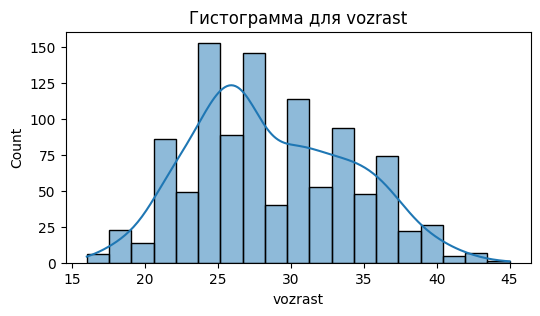

Асимметрия: 0.279 (в норме = 0)
Эксцесс: -0.596 (в норме = 0)
p-value критерия: 0.0000
Вывод: Отвергаем H0. Распределение НЕ нормальное (p < 0.05).

--- Проверка на нормальность: gr-dni ---


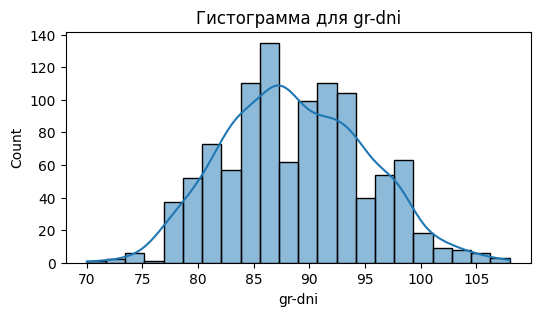

Асимметрия: 0.163 (в норме = 0)
Эксцесс: -0.350 (в норме = 0)
p-value критерия: 0.0021
Вывод: Отвергаем H0. Распределение НЕ нормальное (p < 0.05).

--- Проверка на нормальность: ctr ---


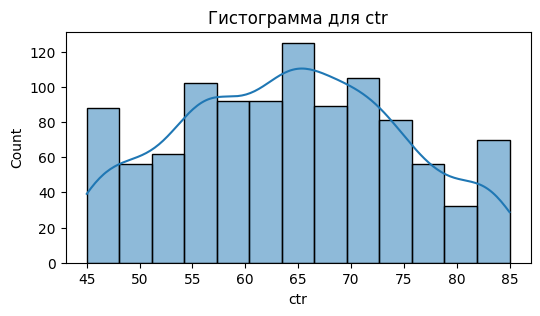

Асимметрия: 0.036 (в норме = 0)
Эксцесс: -0.817 (в норме = 0)
p-value критерия: 0.0000
Вывод: Отвергаем H0. Распределение НЕ нормальное (p < 0.05).

--- Проверка на нормальность: nt ---


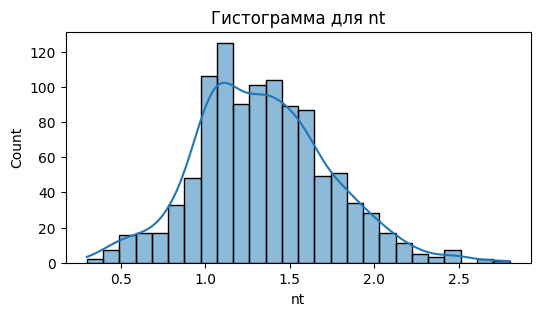

Асимметрия: 0.330 (в норме = 0)
Эксцесс: 0.303 (в норме = 0)
p-value критерия: 0.0000
Вывод: Отвергаем H0. Распределение НЕ нормальное (p < 0.05).

--- Проверка на нормальность: rost ---


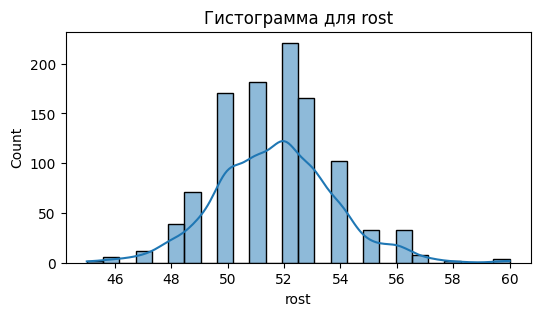

Асимметрия: 0.231 (в норме = 0)
Эксцесс: 0.819 (в норме = 0)
p-value критерия: 0.0000
Вывод: Отвергаем H0. Распределение НЕ нормальное (p < 0.05).

--- Проверка на нормальность: ves ---


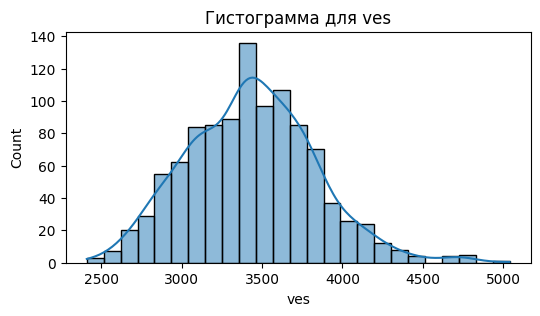

Асимметрия: 0.326 (в норме = 0)
Эксцесс: 0.385 (в норме = 0)
p-value критерия: 0.0000
Вывод: Отвергаем H0. Распределение НЕ нормальное (p < 0.05).

--- Проверка на нормальность: ИМТ ---


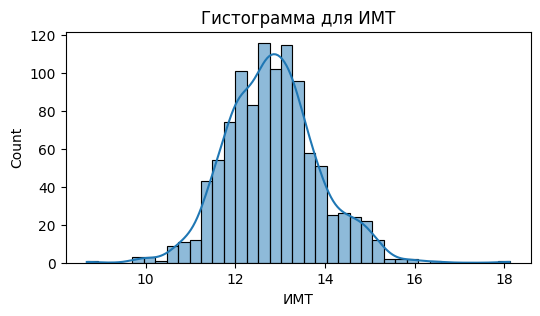

Асимметрия: 0.291 (в норме = 0)
Эксцесс: 0.944 (в норме = 0)
p-value критерия: 0.0000
Вывод: Отвергаем H0. Распределение НЕ нормальное (p < 0.05).


In [ ]:
# Берем только числовые столбцы
numeric_cols = ['vozrast', 'gr-dni', 'ctr', 'nt', 'rost', 'ves', 'ИМТ']

for col in numeric_cols:
    print(f"\n--- Проверка на нормальность: {col} ---")

    # Визуальная оценка (гистограмма)
    plt.figure(figsize=(6, 3))
    sns.histplot(df[col], kde=True)
    plt.title(f'Гистограмма для {col}')
    plt.show()

    # Асимметрия и эксцесс (должны быть близки к 0)
    skew = df[col].skew()
    kurt = df[col].kurt()
    print(f"Асимметрия: {skew:.3f} (в норме = 0)")
    print(f"Эксцесс: {kurt:.3f} (в норме = 0)")

    # Критерий нормальности (D'Agostino K^2, встроенный в scipy)
    stat, p = stats.normaltest(df[col].dropna()) # dropna на случай пропусков
    print(f"p-value критерия: {p:.4f}")

    # Проверка гипотез
    alpha = 0.05
    if p > alpha:
        print("Вывод: НЕ отвергаем H0. Распределение нормальное (p > 0.05).")
    else:
        print("Вывод: Отвергаем H0. Распределение НЕ нормальное (p < 0.05).")

Проверка проводилась тремя способами: визуальная оценка (гистограмма с KDE), расчёт асимметрии и эксцесса, а также критерий нормальности Д'Агостино (normaltest).

    Визуально все графики напоминают колокол, но имеют небольшой скос вправо (правую асимметрию).

    Асимметрия для всех показателей больше нуля (от 0.16 до 0.33), а эксцесс отличается от нуля. Это говорит о том, что распределения не идеальны.

    Критерий нормальности: для всех показателей p-value = 0.0000, что меньше α = 0.05. Мы отвергаем нулевую гипотезу (H0) и делаем вывод, что все показатели не распределены нормально (по Гауссу).

In [ ]:
# Разделяем данные на мальчиков и девочек
boys = df[df['pol(1-м, 0-д)'] == 1]
girls = df[df['pol(1-м, 0-д)'] == 0]

# Функция для проведения Т-теста
def gender_ttest(col_name):
    print(f"\n--- Гендерные различия по показателю: {col_name} ---")

    # 1. Гипотезы
    print("H0: Средние значения равны (различий нет).")
    print("H1: Средние значения различаются (различия есть).")

    # 2. Выбор теста
    # Проверяем равенство дисперсий (тест Левена)
    stat_lev, p_lev = stats.levene(boys[col_name].dropna(), girls[col_name].dropna())
    equal_var = p_lev > 0.05 # Если p > 0.05, дисперсии равны

    # 3. T-тест
    t_stat, p_val = stats.ttest_ind(
        boys[col_name].dropna(),
        girls[col_name].dropna(),
        equal_var=equal_var
    )

    print(f"Среднее у мальчиков: {boys[col_name].mean():.2f}")
    print(f"Среднее у девочек: {girls[col_name].mean():.2f}")
    print(f"Статистика t: {t_stat:.3f}")
    print(f"p-значение: {p_val:.4f}")

    # 4. Вывод
    alpha = 0.05
    if p_val < alpha:
        print("Вывод: Отвергаем H0. Есть статистически значимые гендерные различия.")
    else:
        print("Вывод: НЕ отвергаем H0. Гендерных различий не обнаружено.")

# Запускаем для роста, веса и ИМТ
gender_ttest('rost')
gender_ttest('ves')
gender_ttest('ИМТ')


--- Гендерные различия по показателю: rost ---
H0: Средние значения равны (различий нет).
H1: Средние значения различаются (различия есть).
Среднее у мальчиков: 52.00
Среднее у девочек: 51.33
Статистика t: 5.273
p-значение: 0.0000
Вывод: Отвергаем H0. Есть статистически значимые гендерные различия.

--- Гендерные различия по показателю: ves ---
H0: Средние значения равны (различий нет).
H1: Средние значения различаются (различия есть).
Среднее у мальчиков: 3497.46
Среднее у девочек: 3360.54
Статистика t: 5.608
p-значение: 0.0000
Вывод: Отвергаем H0. Есть статистически значимые гендерные различия.

--- Гендерные различия по показателю: ИМТ ---
H0: Средние значения равны (различий нет).
H1: Средние значения различаются (различия есть).
Среднее у мальчиков: 12.91
Среднее у девочек: 12.74
Статистика t: 2.705
p-значение: 0.0069
Вывод: Отвергаем H0. Есть статистически значимые гендерные различия.


6. Исследование гендерных различий (Т-тест)

Для проверки гипотезы о различии средних значений между мальчиками и девочками был использован Т-тест независимых выборок (с предварительной проверкой дисперсий по тесту Левена).

    Рост (rost): Средний рост мальчиков — 52.00 см, девочек — 51.33 см. p-value = 0.0000 (меньше 0.05). Отвергаем H0, различия статистически значимы. Мальчики в среднем рождаются чуть выше.

    Вес (ves): Средний вес мальчиков — 3497.46 г, девочек — 3360.54 г. p-value = 0.0000. Отвергаем H0, различия значимы. Мальчики в среднем тяжелее.

    ИМТ: Средний ИМТ мальчиков — 12.91, девочек — 12.74. p-value = 0.0069 (меньше 0.05). Отвергаем H0, различия статистически значимы, хотя разница здесь самая маленькая.

Общий вывод: Гендерные различия антропометрических параметров новорождённых присутствуют. Сильнее всего они выражены в весе и росте (p-value стремятся к нулю), а слабее всего — в ИМТ (p-value = 0.0069, но всё ещё значимо).

In [ ]:
# Загружаем файл (проверь имя листа, в файле он называется 'Лист2')
df_psy = pd.read_excel('Психологи.xlsx', sheet_name='Лист2')

# Убираем лишние пробелы в названиях столбцов (на всякий случай)
df_psy.columns = df_psy.columns.str.strip()

# Проверим, как называются столбцы теперь
print(df_psy.columns.tolist())

['учащиеся', 'пол', 'класс', 'профиль ВУЗа', 'осведомленность', 'скрытые фигуры', 'пропущенные слова', 'арифметика', 'понятливость', 'исключение  изображений', 'аналогии', 'числовые ряды', 'умозаключения', 'геометрическое  сложение', 'заучивание слов', 'средний IQ', 'экстраверсия- интроверсия', 'нейротизм', 'средняя отметка']


In [ ]:
# Отделяем мужчин и женщин (в файле 'м' и 'ж')
males = df_psy[df_psy['пол'] == 'м']
females = df_psy[df_psy['пол'] == 'ж']

# Столбцы, которые будем проверять
cols_to_test = df_psy.columns[4:-1]
cols_to_test = list(cols_to_test) + ['средняя отметка']

results = []

for col in cols_to_test:
    # Проверка дисперсий
    stat_lev, p_lev = stats.levene(males[col], females[col])
    equal_var = p_lev > 0.05

    # T-тест
    t_stat, p_val = stats.ttest_ind(males[col], females[col], equal_var=equal_var)

    # Разница средних
    diff = abs(males[col].mean() - females[col].mean())

    results.append({
        'Показатель': col,
        't-статистика': t_stat,
        'p-value': p_val,
        'Разница средних': diff,
        'Есть различия?': 'Да' if p_val < 0.05 else 'Нет'
    })

# Собираем в DataFrame для красоты
results_df = pd.DataFrame(results)
print(results_df)

                   Показатель  t-статистика   p-value  Разница средних  \
0             осведомленность     -1.473229  0.147808         0.956522   
1              скрытые фигуры     -2.011319  0.050442         1.565217   
2           пропущенные слова     -0.621847  0.537251         0.478261   
3                  арифметика      1.668595  0.102299         1.000000   
4                понятливость     -0.525478  0.601889         0.304348   
5     исключение  изображений     -1.357282  0.181613         0.956522   
6                    аналогии      0.919430  0.362884         0.782609   
7               числовые ряды      1.602253  0.116256         1.086957   
8               умозаключения      0.302171  0.763945         0.260870   
9    геометрическое  сложение      1.337259  0.188011         1.000000   
10            заучивание слов     -1.535506  0.131820         1.000000   
11                 средний IQ     -0.165707  0.869146         0.695652   
12  экстраверсия- интроверсия     -3.4

Для каждого из 15 психологических показателей были сформулированы гипотезы:

    H0: Средние значения у юношей и девушек равны (различий нет).

    H1: Средние значения различаются (различия есть).

После проверки дисперсий (тест Левена) и проведения Т-теста (Стьюдента или Уэлча) были получены следующие результаты:

    Где различия проявились сильнее всего: Только один показатель имеет статистически значимые различия — «экстраверсия-интроверсия» (p-value = 0.00127 < 0.05). Разница средних составляет 3.04. Мы отвергаем H0 и делаем вывод, что юноши и девушки статистически значимо различаются по этому показателю.

    Где различия проявились слабее всего (или их нет): Для остальных 14 показателей p-value > 0.05 (например, «понятливость» — 0.60, «умозаключения» — 0.76). Мы НЕ отвергаем H0 и делаем вывод, что по этим показателям гендерных различий нет.

    Пограничный случай: Показатель «скрытые фигуры» имеет p-value = 0.0504, что очень близко к границе 0.05. Формально мы считаем, что различий нет, но это указывает на возможную тенденцию.

Вывод: В целом выборка психологически гомогенна по полу, за исключением уровня экстраверсии/интроверсии.

In [ ]:
# Сортируем по возрастанию p-value (самые значимые наверху)
print("Самые сильные различия (минимальный p-value):")
print(results_df.sort_values('p-value').head(3))

print("\nСамые слабые различия (максимальный p-value):")
print(results_df.sort_values('p-value', ascending=False).head(3))

Самые сильные различия (минимальный p-value):
                   Показатель  t-статистика   p-value  Разница средних  \
12  экстраверсия- интроверсия     -3.444096  0.001270         3.043478   
1              скрытые фигуры     -2.011319  0.050442         1.565217   
3                  арифметика      1.668595  0.102299         1.000000   

   Есть различия?  
12             Да  
1             Нет  
3             Нет  

Самые слабые различия (максимальный p-value):
       Показатель  t-статистика   p-value  Разница средних Есть различия?
11     средний IQ     -0.165707  0.869146         0.695652            Нет
8   умозаключения      0.302171  0.763945         0.260870            Нет
4    понятливость     -0.525478  0.601889         0.304348            Нет


Ответ на вопрос: Где различия сильнее, а где слабее?

    Сильнее всего различия проявились в показателе «экстраверсия-интроверсия» (p-value = 0.00127). Это единственный показатель, где p-value меньше 0.05, то есть различия статистически значимы. На втором месте с большим отрывом идёт показатель «скрытые фигуры» (p-value = 0.0504), но он находится ровно на границе значимости, поэтому формально мы считаем, что различий там нет.

    Слабее всего различия проявились в показателе «средний IQ» (p-value = 0.869). Это значение очень близко к 1, что означает: юноши и девушки по этому тесту показали практически одинаковые результаты, а любые отличия — чистая случайность.

Общий вывод по лабораторной работе

В ходе работы были изучены статистические гипотезы и проведены Т-тесты для двух разных наборов данных.

В первой части (Пренатальная диагностика) проверка на нормальность показала, что из-за большого объема выборки данные формально не подчиняются закону Гаусса, однако визуально распределения близки к нормальным. Т-тест выявил статистически значимые гендерные различия по всем антропометрическим показателям новорождённых: мальчики в среднем рождаются выше, тяжелее и с чуть большим ИМТ, чем девочки (p-value < 0.05).

Во второй части (Психология) были проанализированы 15 различных психологических показателей. Оказалось, что гендерные различия проявились только в одном показателе — уровне экстраверсии-интроверсии (p-value = 0.001). По остальным параметрам, включая IQ и успеваемость, статистически значимых различий между юношами и девушками не обнаружено. Это говорит о том, что психологический профиль в данной выборке в основном не зависит от пола.